<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1 & 2: RBM Class Implementation (Energy & Conditional Probabilities)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

class RBM:
    def __init__(self, num_visible, num_hidden, learning_rate=0.1):
        self.num_visible = num_visible
        self.num_hidden = num_hidden
        self.lr = learning_rate

        # Initialize weights and biases
        self.W = np.random.normal(loc=0.0, scale=0.01, size=(num_visible, num_hidden))
        self.a = np.zeros(num_visible)  # Visible bias
        self.b = np.zeros(num_hidden)   # Hidden bias

    def sigmoid(self, x):
        return 1.0 / (1.0 + np.exp(-np.clip(x, -80, 80)))

    def energy(self, v, h):
        # Task 1: Compute Energy E(v, h) = -a^T v - b^T h - v^T W h
        # Assumes v is shape (batch_size, num_visible) and h is shape (batch_size, num_hidden)
        term1 = -np.dot(v, self.a)
        term2 = -np.dot(h, self.b)
        term3 = -np.sum(np.dot(v, self.W) * h, axis=1)
        return term1 + term2 + term3

    def prob_h_given_v(self, v):
        # Task 2: Compute p(h|v)
        activation = np.dot(v, self.W) + self.b
        return self.sigmoid(activation)

    def prob_v_given_h(self, h):
        # Task 2: Compute p(v|h)
        activation = np.dot(h, self.W.T) + self.a
        return self.sigmoid(activation)

    def free_energy(self, v):
        # Free energy F(v) = -a^T v - sum(log(1 + exp(W v + b)))
        v_bias_term = np.dot(v, self.a)
        wx_b = np.dot(v, self.W) + self.b
        hidden_term = np.sum(np.log(1.0 + np.exp(np.clip(wx_b, -80, 80))), axis=1)
        return -v_bias_term - hidden_term

    def contrastive_divergence(self, v0):
        # Task 3: One-step Contrastive Divergence (CD-1)
        # Positive phase
        ph0 = self.prob_h_given_v(v0)
        h0 = (ph0 > np.random.rand(*ph0.shape)).astype(np.float32)

        # Negative phase
        pv1 = self.prob_v_given_h(h0)
        v1 = (pv1 > np.random.rand(*pv1.shape)).astype(np.float32)
        ph1 = self.prob_h_given_v(v1)

        # Update weights and biases
        batch_size = v0.shape[0]
        self.W += self.lr * (np.dot(v0.T, ph0) - np.dot(v1.T, ph1)) / batch_size
        self.a += self.lr * np.mean(v0 - v1, axis=0)
        self.b += self.lr * np.mean(ph0 - ph1, axis=0)

        # Compute reconstruction error
        recon_error = np.mean((v0 - pv1) ** 2)
        return recon_error

### Task 3: Train the RBM with one-step contrastive divergence

In [ ]:
# Load and binarize MNIST dataset
(x_train, _), (x_test, _) = mnist.load_data()
x_train = (x_train.reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)
x_test = (x_test.reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)

# Initialize RBM
num_visible = 784
num_hidden = 64
rbm = RBM(num_visible, num_hidden, learning_rate=0.1)

epochs = 20
batch_size = 64
num_batches = len(x_train) // batch_size

free_energies = []
recon_errors = []

for epoch in range(epochs):
    np.random.shuffle(x_train)
    epoch_errors = []
    epoch_energies = []
    for i in range(num_batches):
        batch = x_train[i*batch_size : (i+1)*batch_size]
        err = rbm.contrastive_divergence(batch)
        epoch_errors.append(err)
        epoch_energies.append(np.mean(rbm.free_energy(batch)))

    free_energies.append(np.mean(epoch_energies))
    recon_errors.append(np.mean(epoch_errors))
    print(f"Epoch {epoch+1}/{epochs} - Reconstruction Error: {recon_errors[-1]:.4f} - Free Energy: {free_energies[-1]:.4f}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/20 - Reconstruction Error: 0.0537 - Free Energy: -107.6538
Epoch 2/20 - Reconstruction Error: 0.0404 - Free Energy: -169.4334
Epoch 3/20 - Reconstruction Error: 0.0377 - Free Energy: -195.8636
Epoch 4/20 - Reconstruction Error: 0.0362 - Free Energy: -213.1445
Epoch 5/20 - Reconstruction Error: 0.0353 - Free Energy: -226.4131
Epoch 6/20 - Reconstruction Error: 0.0346 - Free Energy: -237.2641
Epoch 7/20 - Reconstruction Error: 0.0341 - Free Energy: -246.8382
Epoch 8/20 - Reconstruction Error: 0.0336 - Free Energy: -255.7605
Epoch 9/20 - Reconstruction Error: 0.0333 - Free Energy: -264.1944
Epoch 10/20 - Reconstruction Error: 0.0330 - Free Energy: -272.4185
Epoch 11/20 - Reconstruction Error: 0.0327 - Free Energy: -279.5351
Epoch 12/20 - Reconstruction Error: 0.0325 - Free Energy: -287.2566
Epoch 13/20 - Reconstruction Error: 0.0323 - Free Energy: -293.4987
Epoch 14/20 - Reconstruction Error: 0.0321 - Free Energy: -298.8210
Epoch 

### Task 4: Plot average free energy and reconstruction error over epochs

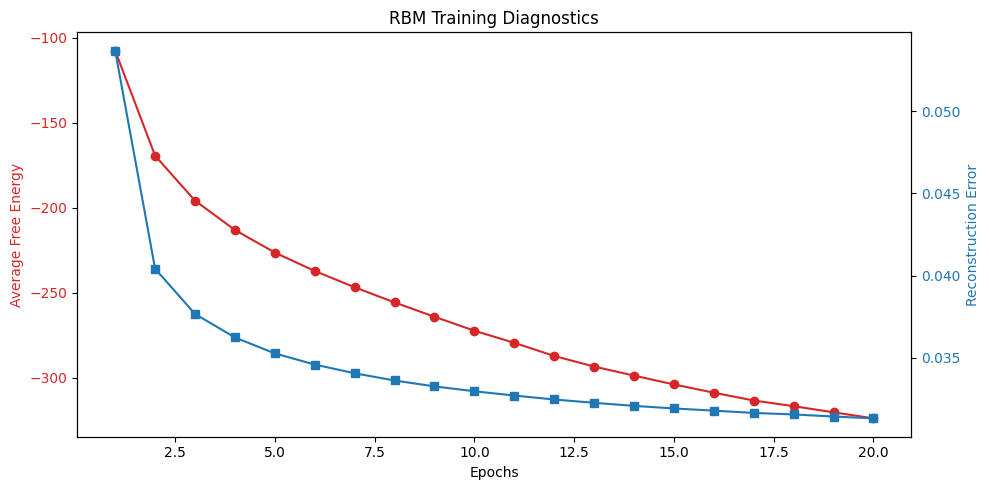

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:red'
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Average Free Energy', color=color)
ax1.plot(range(1, epochs + 1), free_energies, color=color, marker='o')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:blue'
ax2.set_ylabel('Reconstruction Error', color=color)
ax2.plot(range(1, epochs + 1), recon_errors, color=color, marker='s')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('RBM Training Diagnostics')
fig.tight_layout()
plt.show()

### Task 5: Show original and reconstructed samples side by side

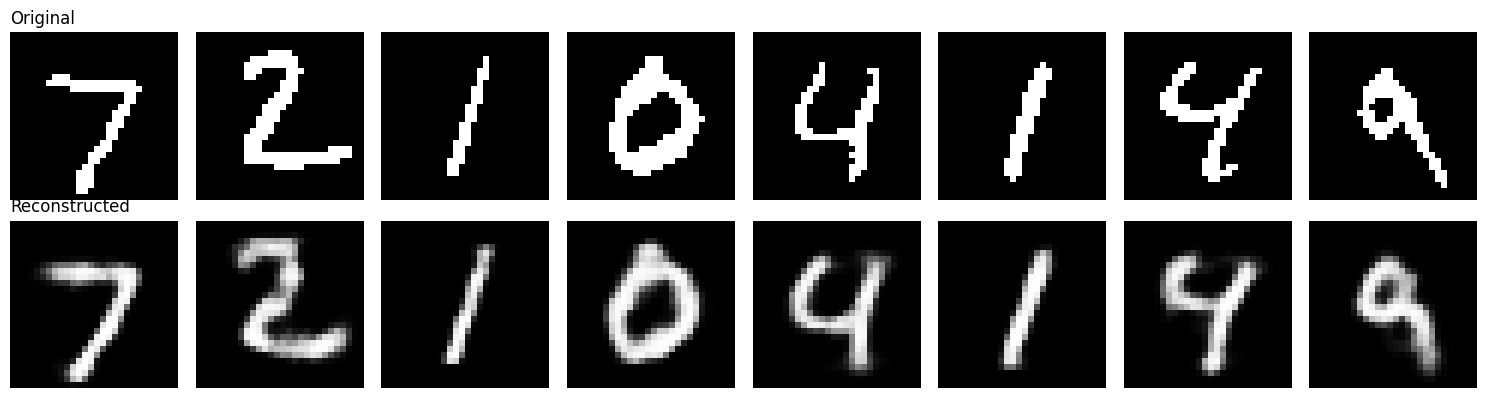

In [ ]:
num_samples = 8
samples = x_test[:num_samples]

# Reconstruct
h_prob = rbm.prob_h_given_v(samples)
reconstructed_prob = rbm.prob_v_given_h(h_prob)

fig, axes = plt.subplots(2, num_samples, figsize=(15, 4))
for i in range(num_samples):
    # Original image
    axes[0, i].imshow(samples[i].reshape(28, 28), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title("Original", loc='left')

    # Reconstructed probabilities
    axes[1, i].imshow(reconstructed_prob[i].reshape(28, 28), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_title("Reconstructed", loc='left')

plt.tight_layout()
plt.show()